In [53]:
import pandas as pd
import re
import nltk
from nltk.corpus import wordnet, stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
import joblib
from sklearn.model_selection import learning_curve
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vivek\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\vivek\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\vivek\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\vivek\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [2]:
!pip install xlrd

In [2]:
df1=pd.read_excel("Business.xlsx")
df2=pd.read_excel("Science.xlsx")
df3=pd.read_excel("Social Science.xlsx")

In [3]:
exclusion_keywords = [
    'Science', 'Social Science', 'Sociology','Psychology', 'Anthropology',
    'Education & Educational Research', 'Behavioral','Food science','History',
    'Environmental Sciences & Ecology'," Women's Studies",'Government & Law','Mathematics','Family Studies']
pattern = '|'.join(exclusion_keywords)
df_businesss = df1[~df1['Research Areas'].str.contains(pattern, case=False, na=False)].copy()

In [4]:
df_businesss["Research Areas"].value_counts()

Research Areas
Business & Economics                                                 3028
Agriculture; Business & Economics                                     157
Business & Economics; Public Administration                            82
Business & Economics; International Relations                          61
Business & Economics; Engineering                                      54
Business & Economics; Development Studies                              40
Business & Economics; Transportation                                   32
Development Studies; Business & Economics                              31
Business & Economics; Communication                                    17
Engineering; Business & Economics                                      13
Business & Economics; Urban Studies                                     8
Business & Economics; Geography                                         7
Development Studies; Business & Economics; Urban Studies                7
Area Studies; Developme

In [5]:
df_businesss["Research Areas"]="Business & Economics"

In [6]:
exclusion_keywords = [
    'Business', 'Economics', 'Social Science', 'Sociology', 
    'Psychology', 'Anthropology', 'Behavioral', 'Management','Social Science', 'Sociology','Psychology', 'Anthropology',
    'Education & Educational Research', 'Behavioral',
    " Women's Studies",'Government & Law','Family Studies']
pattern = '|'.join(exclusion_keywords)
df_science= df2[~df2['Research Areas'].str.contains(pattern, case=False, na=False)].copy()

In [7]:
df_science["Research Areas"].value_counts()

Research Areas
Food Science & Technology                                                    781
Chemistry                                                                    573
Physics                                                                      541
Computer Science; Information Science & Library Science                      359
Zoology                                                                      311
                                                                            ... 
Developmental Biology; Genetics & Heredity                                     1
Biodiversity & Conservation; Genetics & Heredity                               1
Biochemistry & Molecular Biology; Chemistry; Spectroscopy                      1
Biochemistry & Molecular Biology; Biophysics; Chemistry; Computer Science      1
Computer Science; Health Care Sciences & Services; Medical Informatics         1
Name: count, Length: 276, dtype: int64

In [8]:
df_science["Research Areas"]="Science"

In [9]:
invalid_keywords = [
    'Business', 'Economics', 'Science & Technology', 'Computer Science',
    'Engineering', 'Mathematics', 'Environmental', 'Agriculture','Veterinary Sciences',
    'Medical', 'Biomedical', 'Nursing', 'Psychiatry', 'Health','Environmental Sciences & Ecology','Legal Medicine',
    'Rehabilitation', 'Information Science', 'History & Philosophy of Science','Evolutionary Biology','Life Sciences','Genetics & Heredity'
]
pattern = '|'.join(invalid_keywords)
df_social = df3[~df3["Research Areas"].str.contains(pattern, case=False, na=False)].copy()

In [10]:
df_social["Research Areas"].value_counts()

Research Areas
Government & Law                                 1318
Anthropology                                     1178
Sociology                                         790
Social Sciences - Other Topics                    487
International Relations; Government & Law         158
                                                 ... 
Anthropology; Cultural Studies                      1
Anthropology; Psychology                            1
Anthropology; Cultural Studies; Asian Studies       1
Anthropology; Archaeology; Cultural Studies         1
Demography; Sociology                               1
Name: count, Length: 102, dtype: int64

In [11]:
df_social["Research Areas"]="Social Science"

In [12]:
final_df=pd.concat([df_businesss,df_science,df_social],ignore_index=True)

In [13]:
final_df=final_df.dropna(subset=["Abstract"],ignore_index=True)

In [14]:
final_df

,Abstract,Research Areas
0,The main objective of this study is to underst...,Business & Economics
1,The continuity strategy of business innovation...,Business & Economics
2,Purpose: To identify the business values under...,Business & Economics
3,Up to date business is managed by large-scale ...,Business & Economics
4,The rapid development of the internet and its ...,Business & Economics
...,...,...
10094,Ontology in cognitive science has long been do...,Social Science
10095,This 'Families and Relationships' e-Special Is...,Social Science
10096,"In recent years, there is growth of interest f...",Social Science
10097,Although the sociology of deviance and social ...,Social Science


In [15]:
final_df.to_excel("unprocess_abstracts.xlsx",index=False)

In [16]:
df=pd.read_excel("unprocess_abstracts.xlsx")

In [17]:
df.isna().sum()

Abstract          0
Research Areas    0
dtype: int64

In [18]:
df.sample(10)

,Abstract,Research Areas
9259,This article reports the findings from a pheno...,Social Science
7883,The importance of data science in society toda...,Social Science
7151,Mediatization scholarship has extensively anal...,Social Science
5593,Objective: Research methods from social scienc...,Science
1595,Sustainability has emerged as one of most pres...,Business & Economics
8651,Most quantitative studies in the social scienc...,Social Science
3701,Nutritional systems biology may be defined as ...,Science
3190,Visual imagery is a vital component in consume...,Business & Economics
3443,We contact the outside world through our five ...,Business & Economics
8895,New media technologies enable the pervasive an...,Social Science


In [19]:
df["Research Areas"].value_counts()

Research Areas
Social Science          3467
Business & Economics    3449
Science                 3183
Name: count, dtype: int64

In [21]:
lemmatizer=WordNetLemmatizer()
stop_word=set(stopwords.words('english'))
additional_noise_words=[
    'social', 'science', 'business', 'economics',
    'paper', 'study', 'research', 'article', 'results', 'show', 'abstract', 
    'journal', 'author', 'conclusion', 'report', 'citation', 'evaluation', 
    'domain', 'concept', 'factor', 'public', 'scientific', 'scientist', 
    'data', 'information', 'publication', 'cite', 'analyze', 'come', 'people',
    'model', 'requirement', 'implementation', 'discovery', 'argue', 'scholar',
    'environment','association', 'publish', 'western', 'ib', 'library','sociology', 
    'sociologist', 'sociological', 'society'
]
stop_word.update(additional_noise_words)
def clean_text(text):
    text=str(text)
    text=re.sub(r"'s\b", "", text)
    text=text.replace("-"," ")
    text=re.sub(r'[^a-zA-Z\s]','',text)
    words=text.lower().split()
    tagged_word=nltk.pos_tag(words)
    cleaned_words=[]
    for word,tag in tagged_word:
        pos=tag[0].upper()
        tag_dict={
                "J":wordnet.ADJ,
                "N":wordnet.NOUN,
                "V":wordnet.VERB,
                "R":wordnet.ADV
            }
        wordnet_pos=tag_dict.get(pos,wordnet.NOUN)
        lemma_word=lemmatizer.lemmatize(word,wordnet_pos)
        if lemma_word not in stop_word:
            cleaned_words.append(lemma_word)
    return ' '.join(cleaned_words)
df["cleaned_abstract"]=df["Abstract"].apply(clean_text)

In [33]:
print(f"Original abstract:\n{df["Abstract"].iloc[15]}\n")
print(f"Lemmatized abstract:\n{df["cleaned_abstract"].iloc[15]}\n")

Original abstract:
Work-family boundary research debates whether family demands should be integrated or separated from work demands. Our thesis is that the impact of boundary management preferences on business performance depends on the entrepreneur's gender. We also investigate how family-to-business support and business location alter the gender and boundary management preference interaction. Results show that an integration preference enhances business performance for men regardless of family-to-business support or business location. A segmentation preference aids women's business performance, especially among those with high family-to-business support and an independent business. An integration preference yields greater business performance for women with an at-home business.

Lemmatized abstract:
work family boundary debate whether family demand integrate separate work demand thesis impact boundary management preference performance depend entrepreneur gender also investigate famil

In [34]:
df.to_excel("processed_abstracts.xlsx",index=False)

In [39]:
df_cleaned=pd.read_excel("processed_abstracts.xlsx")

In [43]:
df_cleaned["cleaned_abstract"]=df_cleaned["cleaned_abstract"].replace(r'^\s*$',np.nan,regex=True)
df_cleaned=df_cleaned.dropna(subset=["cleaned_abstract"],ignore_index=True)
X=df_cleaned["cleaned_abstract"]
Y=df_cleaned["Research Areas"]

In [44]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,shuffle=True,stratify=Y)

In [45]:
tfidf=TfidfVectorizer(ngram_range=(1,2),max_features=5000)
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

In [46]:
classifier={
    "Logistic Regression":LogisticRegression(max_iter=1000,random_state=42),
    "Decision Trees":DecisionTreeClassifier(random_state=42,max_depth=15),
    "Mutlinomial Naive Bayes":MultinomialNB(),
    "K-Nearest Neighbors(KNN)":KNeighborsClassifier(n_neighbors=15),
    "Suppport Vector Machine":LinearSVC(random_state=42,C=0.1),
    "Random Forest":RandomForestClassifier(n_estimators=100,random_state=42)}

-------------------Logistic Regression------------------------
Accuracy: 92.129%
                      precision    recall  f1-score   support

Business & Economics       0.93      0.94      0.94       690
             Science       0.95      0.91      0.93       637
      Social Science       0.89      0.92      0.90       693

            accuracy                           0.92      2020
           macro avg       0.92      0.92      0.92      2020
        weighted avg       0.92      0.92      0.92      2020



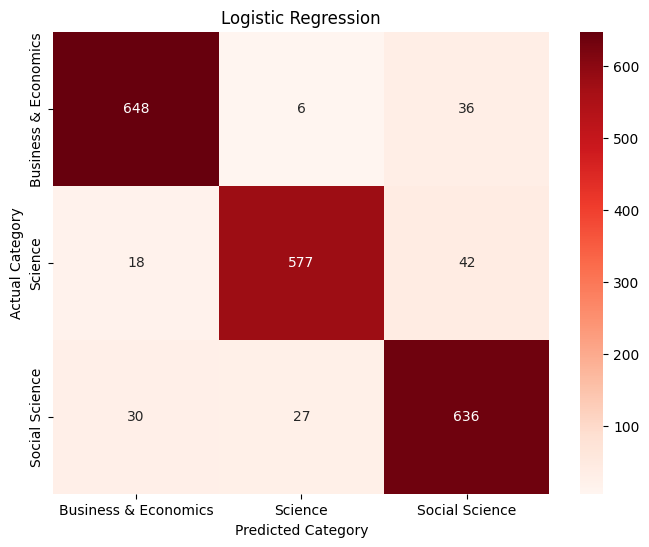

----------------------------------------------------------------------------------------------------

-------------------Decision Trees------------------------
Accuracy: 80.545%
                      precision    recall  f1-score   support

Business & Economics       0.94      0.74      0.83       690
             Science       0.97      0.72      0.82       637
      Social Science       0.66      0.95      0.78       693

            accuracy                           0.81      2020
           macro avg       0.85      0.80      0.81      2020
        weighted avg       0.85      0.81      0.81      2020



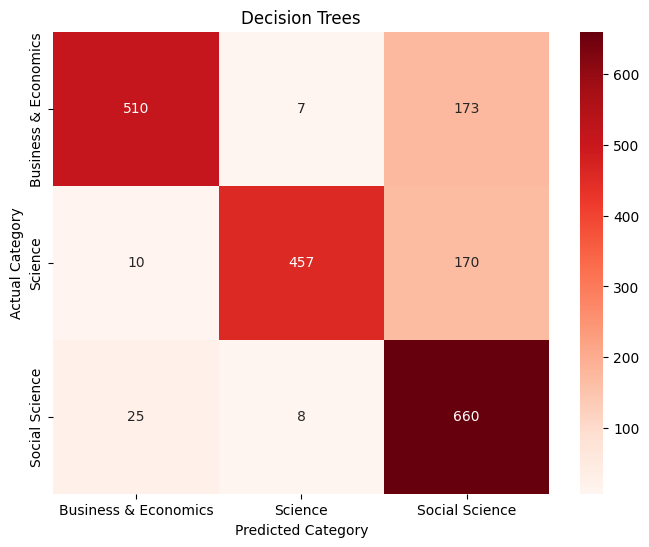

----------------------------------------------------------------------------------------------------

-------------------Mutlinomial Naive Bayes------------------------
Accuracy: 88.119%
                      precision    recall  f1-score   support

Business & Economics       0.92      0.86      0.89       690
             Science       0.96      0.85      0.90       637
      Social Science       0.80      0.93      0.86       693

            accuracy                           0.88      2020
           macro avg       0.89      0.88      0.88      2020
        weighted avg       0.89      0.88      0.88      2020



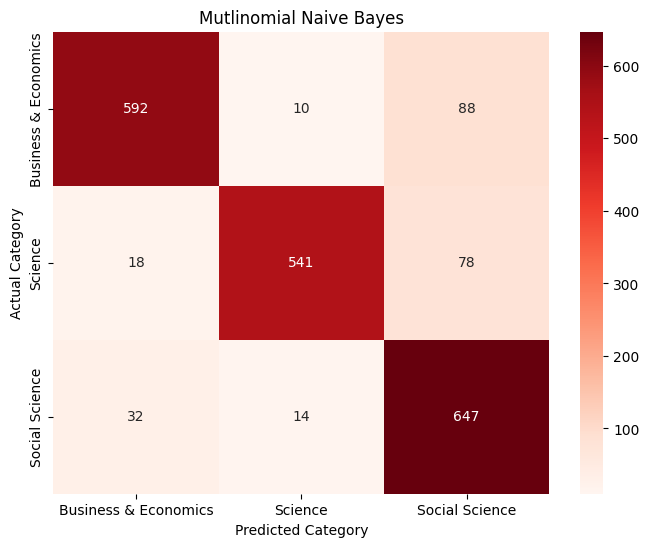

----------------------------------------------------------------------------------------------------

-------------------K-Nearest Neighbors(KNN)------------------------
Accuracy: 87.426%
                      precision    recall  f1-score   support

Business & Economics       0.89      0.88      0.88       690
             Science       0.89      0.88      0.89       637
      Social Science       0.85      0.86      0.85       693

            accuracy                           0.87      2020
           macro avg       0.87      0.87      0.87      2020
        weighted avg       0.87      0.87      0.87      2020



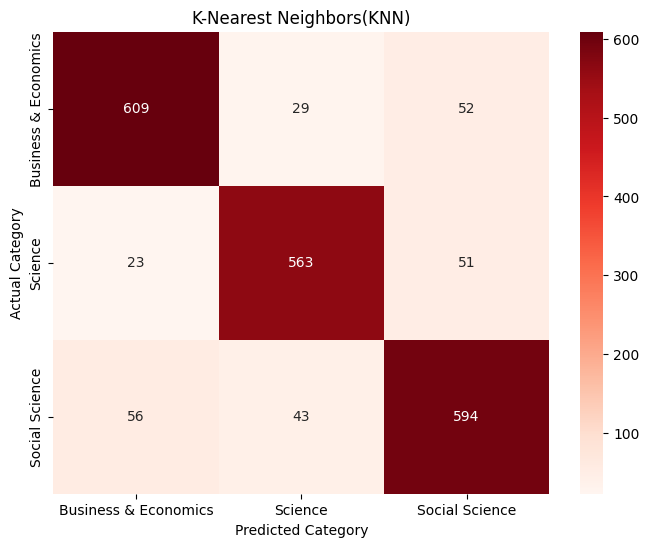

----------------------------------------------------------------------------------------------------

-------------------Suppport Vector Machine------------------------
Accuracy: 92.376%
                      precision    recall  f1-score   support

Business & Economics       0.93      0.94      0.94       690
             Science       0.95      0.91      0.93       637
      Social Science       0.89      0.92      0.91       693

            accuracy                           0.92      2020
           macro avg       0.93      0.92      0.92      2020
        weighted avg       0.92      0.92      0.92      2020



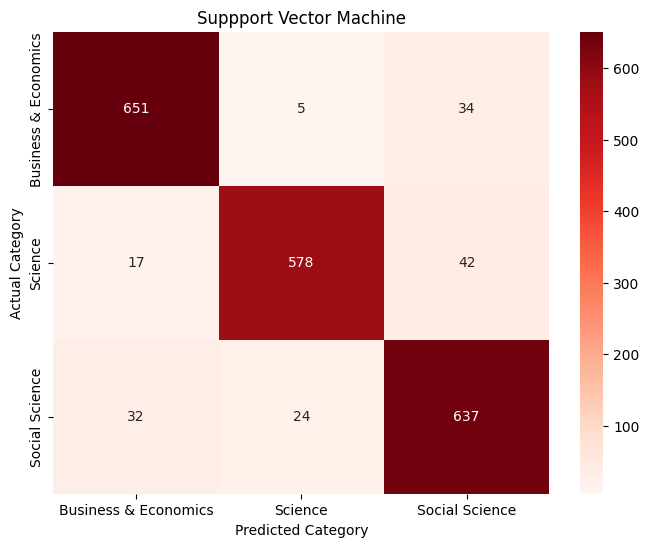

----------------------------------------------------------------------------------------------------

-------------------Random Forest------------------------
Accuracy: 88.564%
                      precision    recall  f1-score   support

Business & Economics       0.91      0.88      0.90       690
             Science       0.94      0.86      0.90       637
      Social Science       0.83      0.91      0.87       693

            accuracy                           0.89      2020
           macro avg       0.89      0.88      0.89      2020
        weighted avg       0.89      0.89      0.89      2020



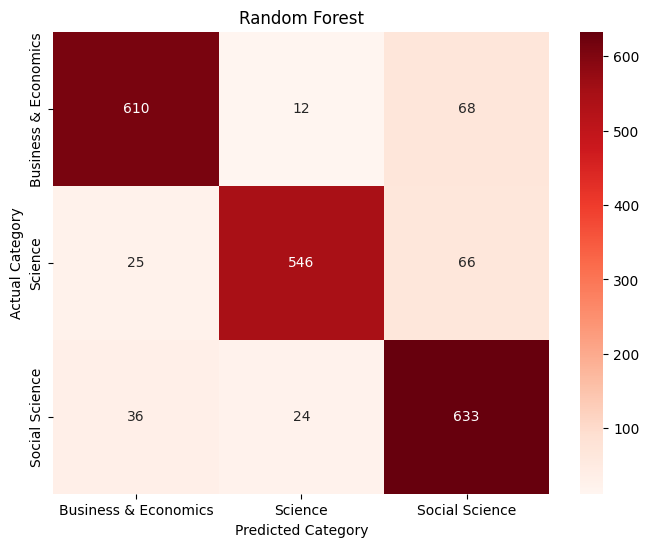

----------------------------------------------------------------------------------------------------



In [47]:
for name, clf in classifier.items():
    print(f"-------------------{name}------------------------")
    clf.fit(X_train_tfidf,Y_train)
    Y_pred=clf.predict(X_test_tfidf)
    print(f"Accuracy: {100*accuracy_score(Y_test,Y_pred):.3f}%") 
    print(classification_report(Y_test,Y_pred))
    cm = confusion_matrix(Y_test, Y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
                xticklabels=clf.classes_, 
                yticklabels=clf.classes_)
    plt.title(f'{name}')
    plt.ylabel('Actual Category')
    plt.xlabel('Predicted Category')
    plt.show()
    print("-"*100+"\n")

In [50]:
final_pipeline=Pipeline([
    ("vectorizer",TfidfVectorizer(ngram_range=(1,2),max_features=5000)),
    ("classifier",LinearSVC(C=0.1,random_state=42))
])
final_pipeline.fit(X_train,Y_train)

,steps,"[('vectorizer', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


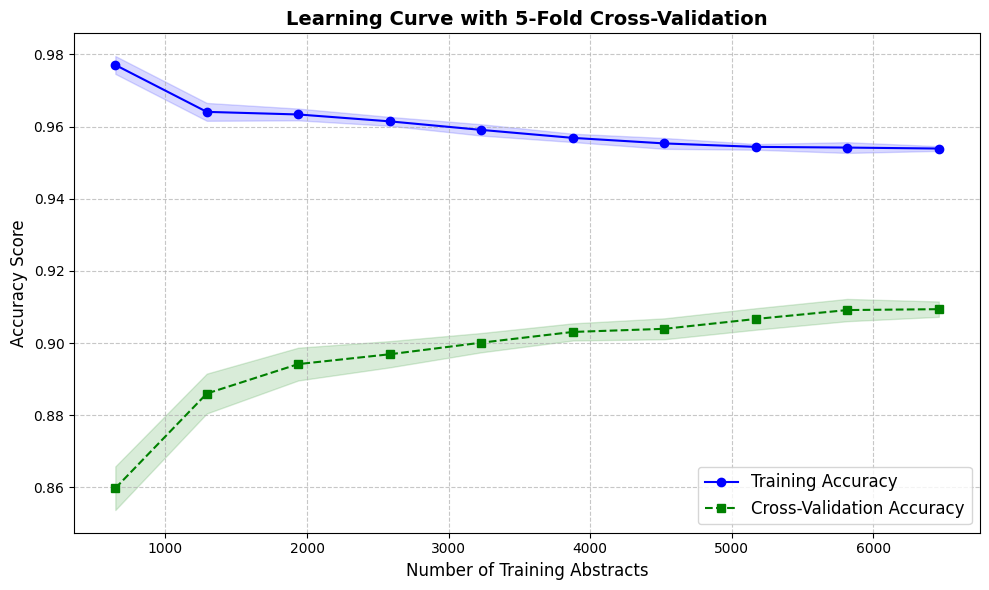

In [52]:
train_sizes, train_scores, test_scores = learning_curve(
    estimator=final_pipeline,     
    X=X_train, 
    y=Y_train,
    cv=5,                      
    n_jobs=-1,               
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy'
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))


plt.plot(train_sizes, train_mean, color='blue', marker='o', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')


plt.plot(train_sizes, test_mean, color='green', marker='s', linestyle='--', label='Cross-Validation Accuracy')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curve with 5-Fold Cross-Validation', fontsize=14, fontweight='bold')
plt.xlabel('Number of Training Abstracts', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right', fontsize=12)
plt.tight_layout()
plt.show()

In [56]:
joblib.dump(final_pipeline,"abstract_classifier.joblib")

['abstract_classifier.joblib']